<a href="https://colab.research.google.com/github/ThomasAlbin/Space-Science-With-Python/blob/main/2026/asteroid_spin_barrier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Spin Barrier: Why Big Asteroids Rarely Spin Fast

Many asteroids are not solid rocks but **rubble piles**: boulders, gravel and dust that came together again after a collision and are held together mainly by their own weak gravity. Spacecraft have even brought samples of three of them back to Earth: Itokawa (Hayabusa), Ryugu (Hayabusa2) and Bennu (OSIRIS-REx).

A rubble pile has a speed limit. Think of a rock on its equator: gravity pulls it inward, while the spin flings it outward (the centrifugal acceleration $\omega^2 R$ in the asteroid's rotating frame). If the asteroid spins too fast, gravity loses and the rock lifts off. For a sphere with radius $R$ and bulk density $\rho$, the mass is $M = \frac{4}{3}\pi R^3 \rho$, and both accelerations are equal when

$$\omega^2 R = \frac{G M}{R^2} = \frac{4}{3}\pi G \rho R$$

The radius cancels! With the rotation period $P = 2\pi/\omega$ we get the **critical period**

$$P_{crit} = \sqrt{\frac{3\pi}{G\rho}}$$

It depends only on the density, not on the size: every rubble pile with the same density has the same speed limit. Small monolithic rocks are a different story: their material strength holds them together, so they can spin much faster.

Do real asteroids obey this limit? Let's check it with about 30,000 measured rotation periods!

In [1]:
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('dark_background')

## The Critical Period

We compute $P_{crit}$ for three bulk densities: 1 g/cm³ (very porous, like a comet), 2 g/cm³ (a typical rubble pile) and 3 g/cm³ (compact rock).

In [2]:
G = 6.6743e-11  # gravitational constant in m^3 kg^-1 s^-2


def critical_period(rho):
    """Critical rotation period (hours) of a strengthless sphere with bulk density rho (kg/m^3)."""
    return np.sqrt(3 * np.pi / (G * rho)) / 3600


densities = [1000, 2000, 3000]  # kg/m^3

for rho in densities:
    print(f"rho = {rho / 1000:.0f} g/cm^3: P_crit = {critical_period(rho):.2f} h")

rho = 1 g/cm^3: P_crit = 3.30 h
rho = 2 g/cm^3: P_crit = 2.33 h
rho = 3 g/cm^3: P_crit = 1.91 h


## Get the Data

The **Asteroid Lightcurve Database (LCDB)** by Brian Warner, Alan Harris and Petr Pravec collects the rotation periods published in the literature. Version 4.0 (September 2021, almost 35,000 asteroids) is archived at NASA's Planetary Data System (PDS); newer versions are available at [minplanet.info](https://minplanet.info/php/lcdb.php). JPL's Small-Body Database also lists periods from the LCDB, but without their quality code and with only a few diameters of small asteroids, which are exactly the ones we need here.

We use the summary table with one row per asteroid, [`lc_summary.csv`](https://sbnarchive.psi.edu/pds4/non_mission/ast-lightcurve-database_V4_0/data/lc_summary.csv). The archive currently answers downloads from scripts with an error (HTTP 403), so open the link in your browser and save the file next to this notebook. In Colab, upload it with the folder icon on the left.

The columns we need:

* `Diam`: diameter in km. Most values are calculated from the absolute magnitude $H$ and an assumed albedo; the others were measured (e.g. by the WISE space telescope, radar or spacecraft). For dark asteroids, the calculated values can be off by more than a factor of two: the LCDB lists Bennu at 0.21 km, while OSIRIS-REx measured 0.49 km.
* `Period`: rotation period in hours.
* `U`: quality code of the period, from 1 (possibly wrong) to 3 (unambiguous), refined with "+" and "-".

The file starts with a block of metadata. The column names follow the line `# Column definitions`, the table starts after the line `# Data`, and missing values are written as `-9.99` or `-`.

In [3]:
text = open("lc_summary.csv", encoding="utf-8").read()

header, table = text.split("# Data")
columns = header.split("# Column definitions")[1].splitlines()[1]
df = pd.read_csv(io.StringIO(columns + "\n" + table.split("\n", 1)[1]), na_values=["-9.99", "-"], low_memory=False)
print(f"{len(df):,} asteroids in the LCDB")

df[["Name", "Diam", "Period", "U"]].head()

34,967 asteroids in the LCDB


,Name,Diam,Period,U
0,Ceres,939.40,9.07417,3
1,Pallas,512.22,7.81320,3
2,Juno,257.88,7.21000,3
3,Vesta,525.00,5.34200,3
4,Astraea,115.00,16.80600,3


We keep the asteroids with a reliable period (quality 2 or better) and a known diameter.

In [4]:
good = df[df["U"].str[0].isin(["2", "3"]) & (df["Period"] > 0) & (df["Diam"] > 0)]
print(f"{len(good):,} asteroids with a reliable period and a diameter")

29,911 asteroids with a reliable period and a diameter


## Big vs. Small

How many asteroids rotate faster than 2.2 hours? We sort them into four size groups: `count` is the number of asteroids in a group, `mean` the fraction that rotates faster.

In [5]:
size = pd.cut(good["Diam"], [0, 0.2, 1, 10, 3000], labels=["< 200 m", "200 m - 1 km", "1 - 10 km", "> 10 km"])
fast = good["Period"] < 2.2
fast.groupby(size, observed=True).agg(["count", "mean"]).round(3)

,count,mean
Diam,,
< 200 m,585,0.646
200 m - 1 km,1910,0.028
1 - 10 km,22367,0.006
> 10 km,5049,0.001


The fastest asteroids (`Period` in hours), and two famous ones: DART's target Didymos and the exception 2001 OE84.

In [6]:
good.sort_values("Period")[["Name", "Diam", "Period"]].head()

,Name,Diam,Period
34703,2017 QG18,0.012,0.003298
34787,2019 BE5,0.028,0.003328
34676,2017 FK,0.010,0.004280
34223,2015 SV6,0.009,0.004900
33702,2010 JL88,0.013,0.006829


In [7]:
famous = good[good["Name"].isin(["Didymos", "2001 OE84"])]
famous[["Name", "Diam", "Period"]]

,Name,Diam,Period
18146,Didymos,0.693,2.2593
32486,2001 OE84,0.647,0.4865


## Visualisation

The classic spin-size diagram: rotation period vs. diameter, both on logarithmic axes, with $P_{crit}$ for the three densities. Didymos and 2001 OE84 are marked.

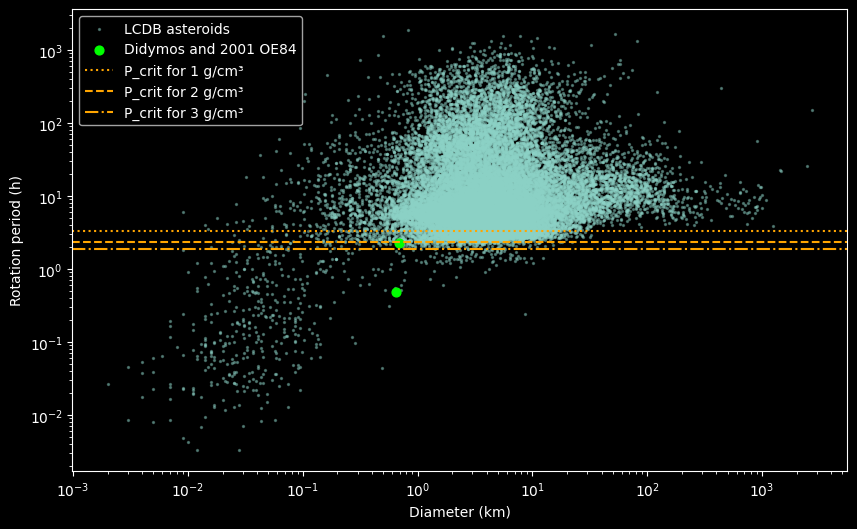

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(good["Diam"], good["Period"], s=2, alpha=0.4, label="LCDB asteroids")
ax.scatter(famous["Diam"], famous["Period"], s=40, color='lime', label="Didymos and 2001 OE84")
for rho, ls in zip(densities, [':', '--', '-.']):
    ax.axhline(critical_period(rho), color='orange', ls=ls, label=f"P_crit for {rho / 1000:.0f} g/cm³")

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel("Diameter (km)")
ax.set_ylabel("Rotation period (h)")
ax.legend()
plt.show()

## Take-Aways

* **The barrier is real:** about two thirds of the asteroids smaller than 200 m rotate faster than 2.2 hours, but fewer than 3 % of those between 200 m and 1 km, and fewer than 1 % of the larger ones. From a few hundred metres to a few tens of kilometres, the lower edge of the cloud is a horizontal line, as $P_{crit}$ predicts: the size cancels out. The biggest asteroids stay well above it.
* **What the barrier tells us:** asteroids larger than a few hundred metres have practically no tensile strength. They are rubble piles held together by gravity. The edge at about 2.2 h fits densities of 2 to 3 g/cm³.
* **The small ones spin in minutes, some in seconds:** the fastest asteroid in this table, 2017 QG18 (about 12 m), rotates once every 12 seconds. Such bodies are held together by their own strength (monolithic rocks) or by cohesion between their grains.
* **Exceptions exist:** 2001 OE84 (about 650 m) rotates in 29 minutes. Gravity alone cannot hold it together, so it must have some internal strength. Many of the other big dots below the barrier are probably wrong periods: most of them come from wide-field surveys, which the LCDB flags in the column `Survey` as results to use with caution for statistics.
* **Didymos sits right at the limit:** DART's target rotates every 2.26 hours and has a small moon, Dimorphos. The moon probably formed from material that Didymos lost when sunlight (the YORP effect) spun it up to the barrier.
* **Extensions:** leave out the survey results (`good[good["Survey"].isna()]`) and plot again: most of the big dots below the barrier disappear. Elongated asteroids reach the limit earlier. Pravec & Harris (2000) give $P_{crit} \approx 3.3\,\mathrm{h}\,\sqrt{(1 + \Delta m)/\rho}$ with $\rho$ in g/cm³ and the lightcurve amplitude $\Delta m$ (columns `AmpMin`/`AmpMax`). Try to colour the plot by amplitude!

## Sources

* Warner, Harris & Pravec (2009): The asteroid lightcurve database. Icarus 202, 134–146. https://doi.org/10.1016/j.icarus.2009.02.003
* Warner, Harris & Pravec (2021): Asteroid Lightcurve Database (LCDB) Bundle V4.0. NASA Planetary Data System. https://doi.org/10.26033/j3xc-3359
* Pravec & Harris (2000): Fast and slow rotation of asteroids. Icarus 148, 12–20. https://doi.org/10.1006/icar.2000.6482
* Walsh (2018): Rubble pile asteroids. Annu. Rev. Astron. Astrophys. 56, 593–624. https://doi.org/10.1146/annurev-astro-081817-052013
* Nakamura, Noguchi, Tanaka et al. (2011): Itokawa dust particles. Science 333, 1113–1116. https://doi.org/10.1126/science.1207758
* Yada, Abe, Okada et al. (2022): Preliminary analysis of the Hayabusa2 samples returned from C-type asteroid Ryugu. Nat. Astron. 6, 214–220. https://doi.org/10.1038/s41550-021-01550-6
* Lauretta, Connolly, Aebersold et al. (2024): Asteroid (101955) Bennu in the laboratory. Meteorit. Planet. Sci. 59, 2453–2486. https://doi.org/10.1111/maps.14227
* Lauretta, DellaGiustina, Bennett et al. (2019): The unexpected surface of asteroid (101955) Bennu. Nature 568, 55–60. https://doi.org/10.1038/s41586-019-1033-6
* Polishook, Moskovitz, Thirouin et al. (2017): The fast spin of near-Earth asteroid (455213) 2001 OE84, revisited after 14 years. Icarus 297, 126–133. https://doi.org/10.1016/j.icarus.2017.06.036
* Rubincam (2000): Radiative spin-up and spin-down of small asteroids. Icarus 148, 2–11. https://doi.org/10.1006/icar.2000.6485
* Walsh, Richardson & Michel (2008): Rotational breakup as the origin of small binary asteroids. Nature 454, 188–191. https://doi.org/10.1038/nature07078
* Daly, Ernst, Barnouin et al. (2023): Successful kinetic impact into an asteroid for planetary defence. Nature 616, 443–447. https://doi.org/10.1038/s41586-023-05810-5